##Tea Leaf Disease Classification with a CNN from Scratch

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!unzip -q "/content/drive/MyDrive/CVPR Assignment/Tea Leaf Disease Image.zip" -d /content/tea_raw

Mounted at /content/drive


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


from torchvision import datasets, transforms
from torch.utils.data import DataLoader


import matplotlib.pyplot as plt
import numpy as np
import os, urllib.request, zipfile


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


torch.manual_seed(0)
np.random.seed(0)

Using device: cuda


In [ ]:
from PIL import Image, ImageOps
import random

RAW_DIR   = "/content/tea_raw"     # unzipped the dataset
SPLIT_DIR = "/content/tea_split"   # the new train/validation folders go
SAVE_SIZE = 256                    # shrink each photo once to 256x256
VAL_RATIO = 0.2                    # 20% validation, 80% training
IMG_EXT   = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

#Find the folder that holds the class folders
def find_class_root(root):
    for current, subdirs, _ in os.walk(root):
        subdirs = [d for d in subdirs if not d.startswith(('.', '__'))]
        if len(subdirs) >= 2 and all(
            any(f.lower().endswith(IMG_EXT) for f in os.listdir(os.path.join(current, d)))
            for d in subdirs):
            return current, sorted(subdirs)
    return None, None

class_root, classes = find_class_root(RAW_DIR)
print("Class folders found in:", class_root)
print("Classes:", classes)

#Shuffle each class, split 80/20, resize, and save
random.seed(0)
for cls in classes:
    files = [f for f in os.listdir(os.path.join(class_root, cls))
             if f.lower().endswith(IMG_EXT)]
    random.shuffle(files)
    n_val = int(len(files) * VAL_RATIO)
    splits = {"validation": files[:n_val], "train": files[n_val:]}

    for split, flist in splits.items():
        out_dir = os.path.join(SPLIT_DIR, split, cls)
        os.makedirs(out_dir, exist_ok=True)
        for f in flist:
            img = Image.open(os.path.join(class_root, cls, f))
            img = ImageOps.exif_transpose(img).convert("RGB")
            img = img.resize((SAVE_SIZE, SAVE_SIZE))
            img.save(os.path.join(out_dir, os.path.splitext(f)[0] + ".jpg"), quality=95)

    print(f"{cls:15s} train={len(splits['train'])}  validation={n_val}")

#Point to the train and validation folders
train_dir = os.path.join(SPLIT_DIR, "train")
val_dir   = os.path.join(SPLIT_DIR, "validation")
print("train:", os.listdir(train_dir))
print("val  :", os.listdir(val_dir))

Class folders found in: /content/tea_raw
Classes: ['Blight', 'Healthy_Leaf', 'Helopeltis', 'Red_Rust']
Blight          train=444  validation=111
Healthy_Leaf    train=520  validation=130
Helopeltis      train=540  validation=135
Red_Rust        train=496  validation=124
train: ['Healthy_Leaf', 'Blight', 'Red_Rust', 'Helopeltis']
val  : ['Healthy_Leaf', 'Blight', 'Red_Rust', 'Helopeltis']


In [ ]:
IMG_SIZE = 128
BATCH_SIZE = 32

#Basic transform: just resize + convert to tensor. No augmentation
basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

# ImageFolder reads images and labels them by their folder name
# (Blight=0, Healthy_Leaf=1, Helopeltis=2, Red_Rust=3)
train_ds = datasets.ImageFolder(train_dir, transform=basic_transform)
val_ds   = datasets.ImageFolder(val_dir,   transform=basic_transform)

# DataLoader feeds the images to the model in small batches
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)

print("Classes:", train_ds.classes)
print("Train images:", len(train_ds))
print("Val images  :", len(val_ds))

Classes: ['Blight', 'Healthy_Leaf', 'Helopeltis', 'Red_Rust']
Train images: 2000
Val images  : 500


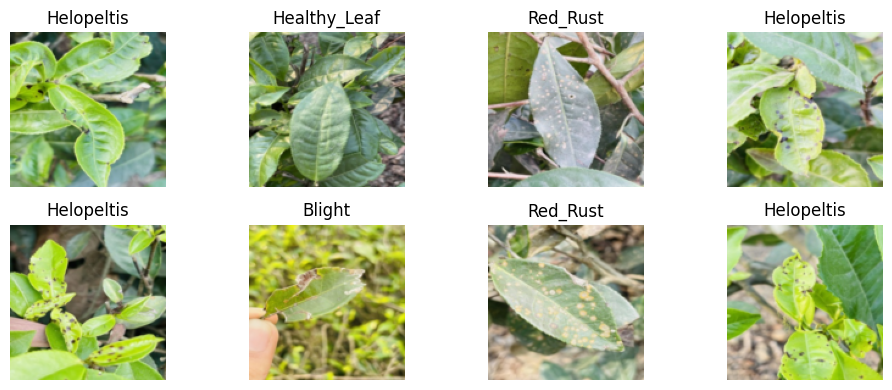

In [ ]:
# Grab one batch
images, labels = next(iter(train_loader))
class_names = train_ds.classes

plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    # tensor shape is [C, H, W]; matplotlib wants [H, W, C]
    plt.imshow(images[i].permute(1, 2, 0))
    plt.title(class_names[labels[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, p_dropout=0.0):
        super().__init__()
        #Feature extractor: 3 convolution layers
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)   # 3 -> 16 filters
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)  # 16 -> 32 filters
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)  # 32 -> 64 filters
        self.pool  = nn.MaxPool2d(2, 2)                           # halves H and W

        #Classification head
        self.dropout = nn.Dropout(p_dropout)          # off by default (Round 1)
        self.fc1 = nn.Linear(64 * 16 * 16, 128)       # flattened features -> 128
        self.fc2 = nn.Linear(128, 4)                  # 128 -> 4 classes (tea)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # 128 -> 64
        x = self.pool(F.relu(self.conv2(x)))   # 64  -> 32
        x = self.pool(F.relu(self.conv3(x)))   # 32  -> 16
        x = torch.flatten(x, 1)                # make one long vector per image
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)                        # raw scores (logits) for the 4 classes
        return x

# Build the model (no dropout for Round 1)
model = SimpleCNN(p_dropout=0.0).to(device)
print(model)

n_params = sum(p.numel() for p in model.parameters())
print(f"\nTotal trainable parameters: {n_params:,}")

SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.0, inplace=False)
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=4, bias=True)
)

Total trainable parameters: 2,121,380


In [ ]:
def train_model(model, train_loader, val_loader, epochs=15, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    #record these each epoch so can plot curves afterwards
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):

        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)

            optimizer.zero_grad()          # reset previous nudges
            outputs = model(imgs)          # forward pass -> scores
            loss = criterion(outputs, labels)
            loss.backward()                # backprop
            optimizer.step()               # update weights

            running_loss += loss.item() * imgs.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        train_loss = running_loss / total
        train_acc = correct / total


        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():              # no learning here, only checking
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                running_loss += loss.item() * imgs.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)
        val_loss = running_loss / total
        val_acc = correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch+1:2d}/{epochs}  "
              f"train_loss={train_loss:.3f} train_acc={train_acc:.3f}  |  "
              f"val_loss={val_loss:.3f} val_acc={val_acc:.3f}")

    return history

# Train Round 1
history_plain = train_model(model, train_loader, val_loader, epochs=15)

Epoch  1/15  train_loss=1.215 train_acc=0.443  |  val_loss=1.050 val_acc=0.564
Epoch  2/15  train_loss=0.958 train_acc=0.596  |  val_loss=0.903 val_acc=0.630
Epoch  3/15  train_loss=0.843 train_acc=0.645  |  val_loss=0.776 val_acc=0.674
Epoch  4/15  train_loss=0.716 train_acc=0.721  |  val_loss=0.762 val_acc=0.678
Epoch  5/15  train_loss=0.605 train_acc=0.770  |  val_loss=0.664 val_acc=0.730
Epoch  6/15  train_loss=0.446 train_acc=0.835  |  val_loss=0.652 val_acc=0.762
Epoch  7/15  train_loss=0.343 train_acc=0.877  |  val_loss=0.584 val_acc=0.778
Epoch  8/15  train_loss=0.241 train_acc=0.917  |  val_loss=0.610 val_acc=0.800
Epoch  9/15  train_loss=0.166 train_acc=0.949  |  val_loss=0.630 val_acc=0.834
Epoch 10/15  train_loss=0.112 train_acc=0.964  |  val_loss=0.595 val_acc=0.830
Epoch 11/15  train_loss=0.071 train_acc=0.976  |  val_loss=0.744 val_acc=0.840
Epoch 12/15  train_loss=0.094 train_acc=0.969  |  val_loss=0.630 val_acc=0.824
Epoch 13/15  train_loss=0.057 train_acc=0.985  |  va

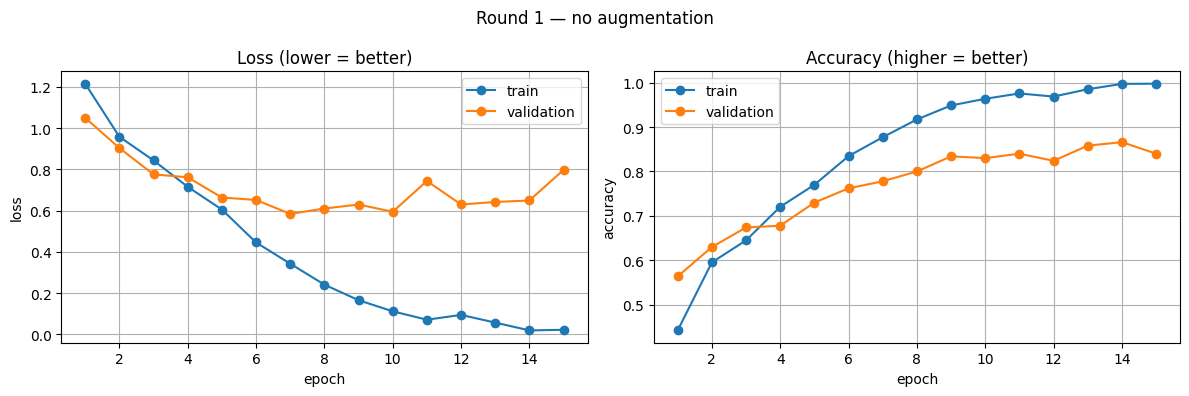

In [ ]:
def plot_history(history, title=""):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(epochs, history["train_loss"], "o-", label="train")
    ax1.plot(epochs, history["val_loss"],   "o-", label="validation")
    ax1.set_title("Loss (lower = better)")
    ax1.set_xlabel("epoch"); ax1.set_ylabel("loss"); ax1.legend(); ax1.grid(True)

    ax2.plot(epochs, history["train_acc"], "o-", label="train")
    ax2.plot(epochs, history["val_acc"],   "o-", label="validation")
    ax2.set_title("Accuracy (higher = better)")
    ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy"); ax2.legend(); ax2.grid(True)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(history_plain, "Round 1 — no augmentation")

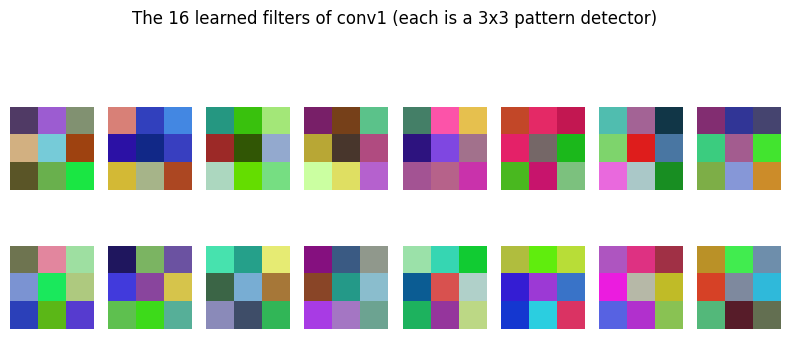

In [ ]:
#Show the 16 filters of the first conv layer
weights = model.conv1.weight.data.clone().cpu()   # shape: [16, 3, 3, 3]

# Scale weights to [0,1] so we can display them as small colour images
w_min, w_max = weights.min(), weights.max()
weights = (weights - w_min) / (w_max - w_min + 1e-8)

plt.figure(figsize=(8, 4))
for i in range(16):
    plt.subplot(2, 8, i + 1)
    plt.imshow(weights[i].permute(1, 2, 0))       # [3,3,3] -> [3,3,3] as RGB
    plt.axis("off")
plt.suptitle("The 16 learned filters of conv1 (each is a 3x3 pattern detector)")
plt.tight_layout()
plt.show()

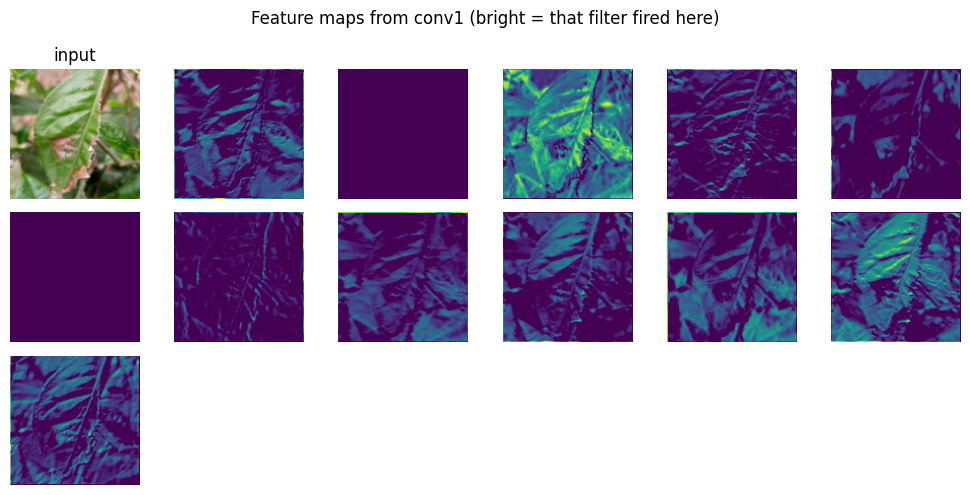

In [ ]:
#Show feature maps: how conv1 responds to one real image
img, label = val_ds[0]                         # one validation image
img_batch = img.unsqueeze(0).to(device)        # add batch dimension

model.eval()
with torch.no_grad():
    feature_maps = F.relu(model.conv1(img_batch)).cpu()[0]   # shape: [16, 128, 128]

plt.figure(figsize=(10, 5))
# original image
plt.subplot(3, 6, 1)
plt.imshow(img.permute(1, 2, 0)); plt.title("input"); plt.axis("off")
# first 12 feature maps
for i in range(12):
    plt.subplot(3, 6, i + 2)
    plt.imshow(feature_maps[i], cmap="viridis")
    plt.axis("off")
plt.suptitle("Feature maps from conv1 (bright = that filter fired here)")
plt.tight_layout()
plt.show()

Last conv layer (conv3) output shape: (64, 32, 32)


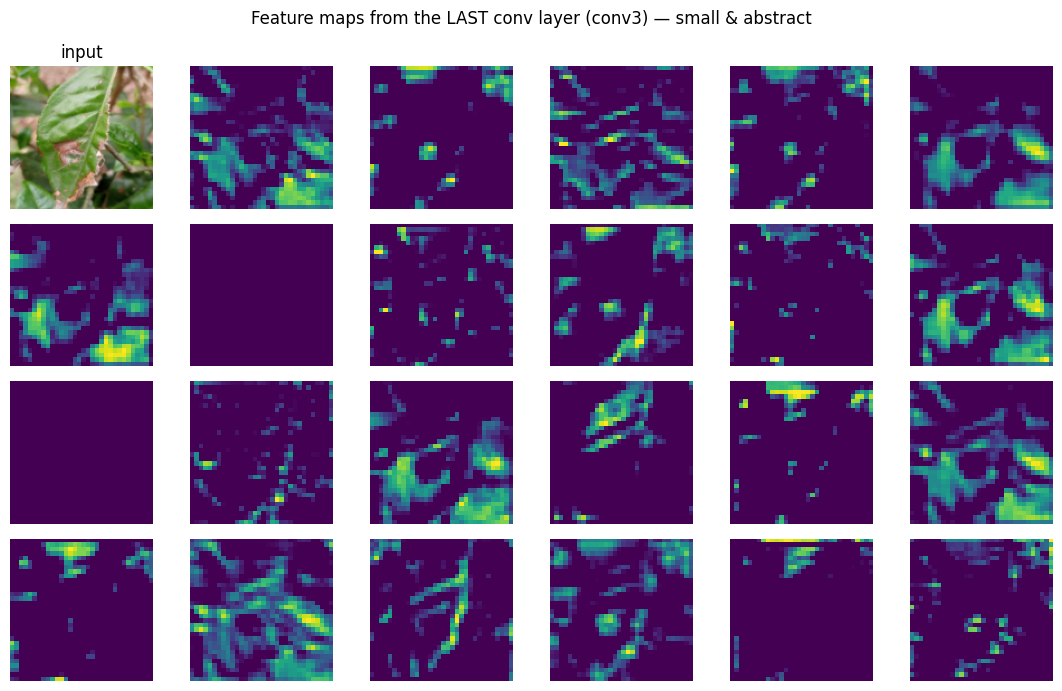

In [ ]:
model.eval()
img, _ = val_ds[0]                          # one validation image
x = img.unsqueeze(0).to(device)


with torch.no_grad():
    x = model.pool(F.relu(model.conv1(x)))       # after block 1 -> 16 × 64 × 64
    x = model.pool(F.relu(model.conv2(x)))       # after block 2 -> 32 × 32 × 32
    last_maps = F.relu(model.conv3(x)).cpu()[0]  # conv3 output   -> 64 × 32 × 32

print("Last conv layer (conv3) output shape:", tuple(last_maps.shape))

plt.figure(figsize=(11, 7))
plt.subplot(4, 6, 1)
plt.imshow(img.permute(1, 2, 0)); plt.title("input"); plt.axis("off")
for i in range(23):                          # show 23 of the 64 feature maps
    plt.subplot(4, 6, i + 2)
    plt.imshow(last_maps[i], cmap="viridis")
    plt.axis("off")
plt.suptitle("Feature maps from the LAST conv layer (conv3) — small & abstract")
plt.tight_layout()
plt.show()

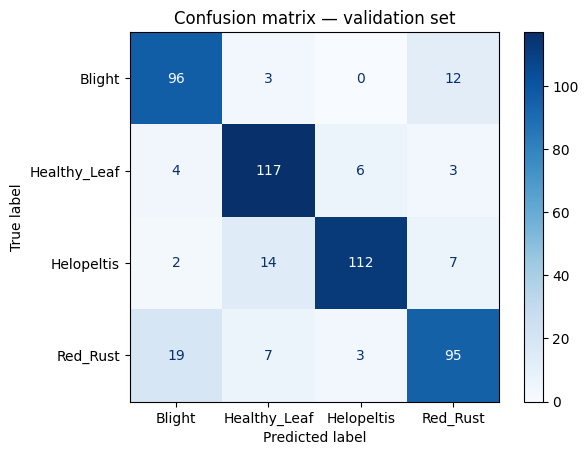

              precision    recall  f1-score   support

      Blight       0.79      0.86      0.83       111
Healthy_Leaf       0.83      0.90      0.86       130
  Helopeltis       0.93      0.83      0.88       135
    Red_Rust       0.81      0.77      0.79       124

    accuracy                           0.84       500
   macro avg       0.84      0.84      0.84       500
weighted avg       0.84      0.84      0.84       500



In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

def get_predictions(model, loader):
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            outputs = model(imgs.to(device))
            preds.append(outputs.argmax(1).cpu())
            targets.append(labels)
    return torch.cat(preds).numpy(), torch.cat(targets).numpy()

#Round 1 model on the validation set
y_pred, y_true = get_predictions(model, val_loader)
class_names = val_ds.classes            # ['Blight', 'Healthy_Leaf', 'Helopeltis', 'Red_Rust']

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix — validation set")
plt.show()

# Per-class precision, recall, f1
print(classification_report(y_true, y_pred, target_names=class_names))

In [ ]:
#Training transform WITH augmentation
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),                 # flip left-right
    transforms.RandomRotation(15),                     # small rotations
    transforms.ColorJitter(brightness=0.2, contrast=0.2),  # lighting changes
    transforms.ToTensor(),
])

#Validation transform stays basic (no augmentation)
val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

train_ds_aug = datasets.ImageFolder(train_dir, transform=train_transform)
val_ds_clean = datasets.ImageFolder(val_dir,   transform=val_transform)

train_loader_aug = DataLoader(train_ds_aug, batch_size=BATCH_SIZE, shuffle=True)
val_loader_clean = DataLoader(val_ds_clean, batch_size=BATCH_SIZE, shuffle=False)

print("Augmented training pipeline ready.")

Augmented training pipeline ready.


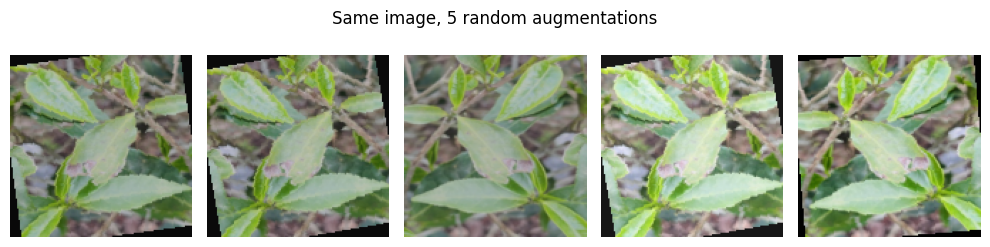

In [ ]:
# See the SAME image augmented differently each time
sample_img, _ = train_ds_aug[0]
plt.figure(figsize=(10, 2.5))
for i in range(5):
    aug_img, _ = train_ds_aug[0]     # re-fetching re-applies random transforms
    plt.subplot(1, 5, i + 1)
    plt.imshow(aug_img.permute(1, 2, 0))
    plt.axis("off")
plt.suptitle("Same image, 5 random augmentations")
plt.tight_layout()
plt.show()

Epoch  1/30  train_loss=1.267 train_acc=0.405  |  val_loss=1.075 val_acc=0.550
Epoch  2/30  train_loss=1.065 train_acc=0.533  |  val_loss=0.988 val_acc=0.568
Epoch  3/30  train_loss=0.979 train_acc=0.592  |  val_loss=0.897 val_acc=0.626
Epoch  4/30  train_loss=0.874 train_acc=0.638  |  val_loss=0.819 val_acc=0.636
Epoch  5/30  train_loss=0.835 train_acc=0.660  |  val_loss=0.748 val_acc=0.688
Epoch  6/30  train_loss=0.733 train_acc=0.704  |  val_loss=0.677 val_acc=0.750
Epoch  7/30  train_loss=0.685 train_acc=0.725  |  val_loss=0.697 val_acc=0.742
Epoch  8/30  train_loss=0.684 train_acc=0.735  |  val_loss=0.610 val_acc=0.788
Epoch  9/30  train_loss=0.656 train_acc=0.746  |  val_loss=0.641 val_acc=0.752
Epoch 10/30  train_loss=0.656 train_acc=0.749  |  val_loss=0.598 val_acc=0.760
Epoch 11/30  train_loss=0.609 train_acc=0.758  |  val_loss=0.587 val_acc=0.796
Epoch 12/30  train_loss=0.562 train_acc=0.778  |  val_loss=0.551 val_acc=0.804
Epoch 13/30  train_loss=0.565 train_acc=0.785  |  va

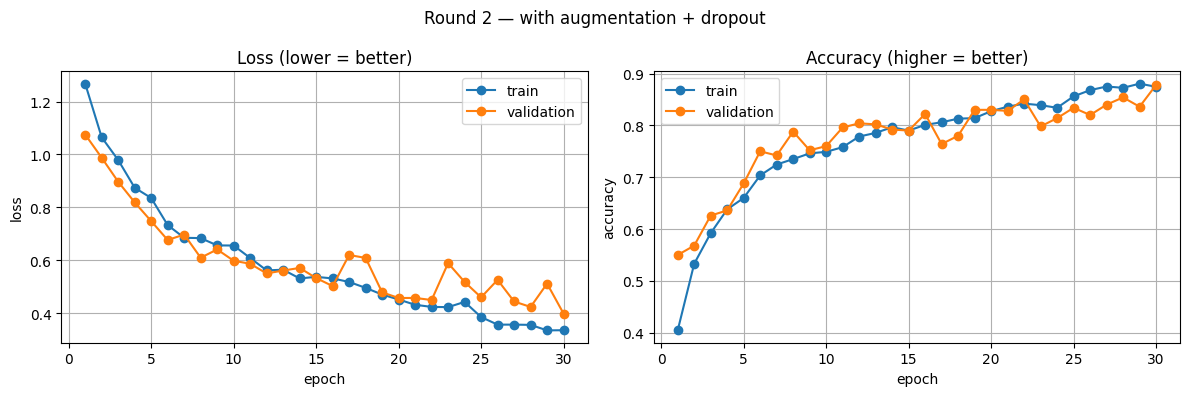

In [ ]:
model_aug = SimpleCNN(p_dropout=0.5).to(device)

history_aug = train_model(model_aug, train_loader_aug, val_loader_clean, epochs=30)
plot_history(history_aug, "Round 2 — with augmentation + dropout")

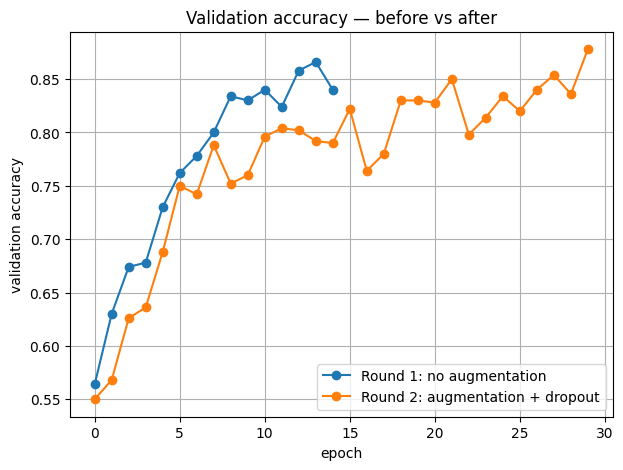

Best val acc  (Round 1): 0.866
Best val acc  (Round 2): 0.878


In [ ]:
plt.figure(figsize=(7, 5))
plt.plot(history_plain["val_acc"], "o-", label="Round 1: no augmentation")
plt.plot(history_aug["val_acc"],   "o-", label="Round 2: augmentation + dropout")
plt.title("Validation accuracy — before vs after")
plt.xlabel("epoch"); plt.ylabel("validation accuracy")
plt.legend(); plt.grid(True)
plt.show()

print(f"Best val acc  (Round 1): {max(history_plain['val_acc']):.3f}")
print(f"Best val acc  (Round 2): {max(history_aug['val_acc']):.3f}")

Last conv layer (conv3) output shape: (64, 32, 32)


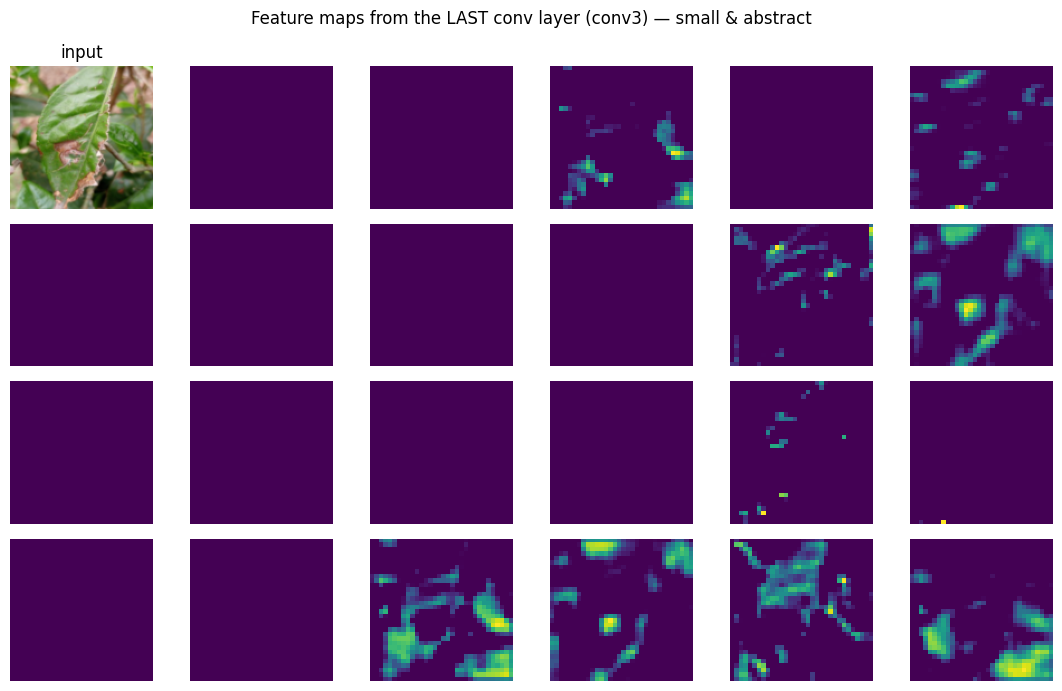

In [ ]:
model_aug.eval()
img, _ = val_ds[0]                          # one validation image
x = img.unsqueeze(0).to(device)


with torch.no_grad():
    x = model_aug.pool(F.relu(model_aug.conv1(x)))       # after block 1 -> 16 × 64 × 64
    x = model_aug.pool(F.relu(model_aug.conv2(x)))       # after block 2 -> 32 × 32 × 32
    last_maps = F.relu(model_aug.conv3(x)).cpu()[0]  # conv3 output   -> 64 × 32 × 32

print("Last conv layer (conv3) output shape:", tuple(last_maps.shape))

plt.figure(figsize=(11, 7))
plt.subplot(4, 6, 1)
plt.imshow(img.permute(1, 2, 0)); plt.title("input"); plt.axis("off")
for i in range(23):                          # show 23 of the 64 feature maps
    plt.subplot(4, 6, i + 2)
    plt.imshow(last_maps[i], cmap="viridis")
    plt.axis("off")
plt.suptitle("Feature maps from the LAST conv layer (conv3) — small & abstract")
plt.tight_layout()
plt.show()

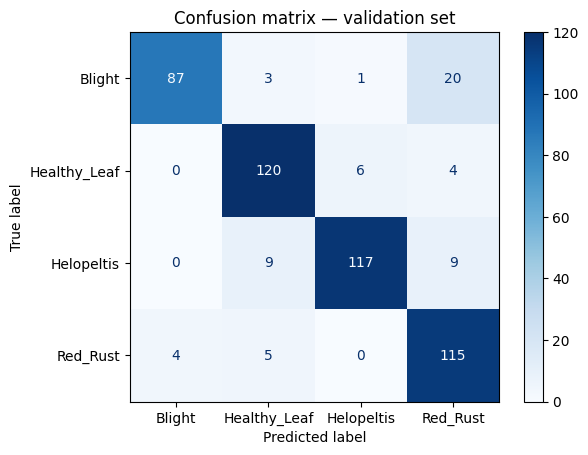

              precision    recall  f1-score   support

      Blight       0.96      0.78      0.86       111
Healthy_Leaf       0.88      0.92      0.90       130
  Helopeltis       0.94      0.87      0.90       135
    Red_Rust       0.78      0.93      0.85       124

    accuracy                           0.88       500
   macro avg       0.89      0.88      0.88       500
weighted avg       0.89      0.88      0.88       500



In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

def get_predictions(model, loader):
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            outputs = model(imgs.to(device))
            preds.append(outputs.argmax(1).cpu())
            targets.append(labels)
    return torch.cat(preds).numpy(), torch.cat(targets).numpy()

#Round 2 model on the clean validation set
y_pred, y_true = get_predictions(model_aug, val_loader_clean)
class_names = val_ds_clean.classes            # ['Blight', 'Healthy_Leaf', 'Helopeltis', 'Red_Rust']

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix — validation set")
plt.show()

# Per-class precision, recall, f1
print(classification_report(y_true, y_pred, target_names=class_names))

Epoch  1/30  train_loss=1.283 train_acc=0.391  |  val_loss=1.148 val_acc=0.536
Epoch  2/30  train_loss=1.092 train_acc=0.522  |  val_loss=0.988 val_acc=0.606
Epoch  3/30  train_loss=0.918 train_acc=0.597  |  val_loss=0.804 val_acc=0.664
Epoch  4/30  train_loss=0.862 train_acc=0.643  |  val_loss=0.922 val_acc=0.614
Epoch  5/30  train_loss=0.757 train_acc=0.691  |  val_loss=0.677 val_acc=0.728
Epoch  6/30  train_loss=0.712 train_acc=0.717  |  val_loss=0.625 val_acc=0.752
Epoch  7/30  train_loss=0.678 train_acc=0.731  |  val_loss=0.641 val_acc=0.746
Epoch  8/30  train_loss=0.696 train_acc=0.733  |  val_loss=0.620 val_acc=0.766
Epoch  9/30  train_loss=0.605 train_acc=0.758  |  val_loss=0.555 val_acc=0.806
Epoch 10/30  train_loss=0.604 train_acc=0.766  |  val_loss=0.574 val_acc=0.792
Epoch 11/30  train_loss=0.557 train_acc=0.792  |  val_loss=0.596 val_acc=0.778
Epoch 12/30  train_loss=0.554 train_acc=0.791  |  val_loss=0.560 val_acc=0.776
Epoch 13/30  train_loss=0.521 train_acc=0.806  |  va

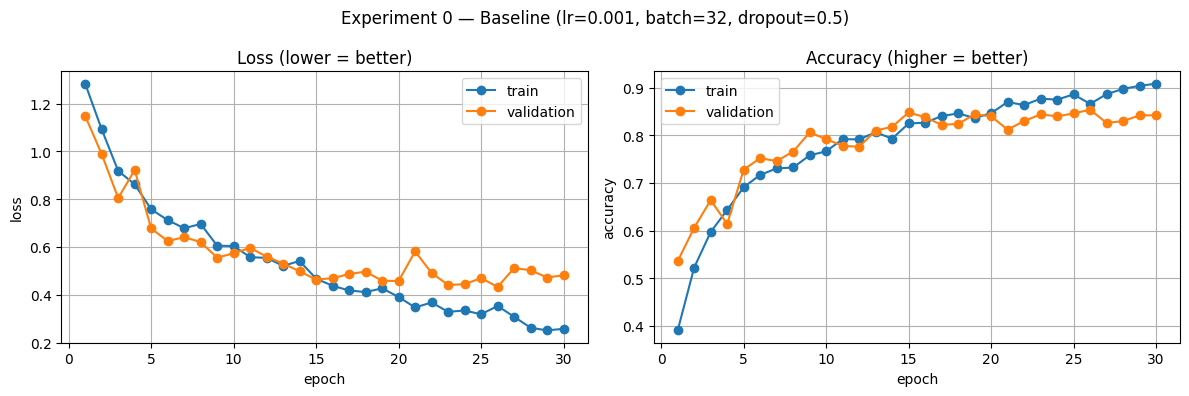

In [ ]:
# Experiment 0: Baseline
torch.manual_seed(0)
model_base = SimpleCNN(p_dropout=0.5).to(device)

history_base = train_model(model_base, train_loader_aug, val_loader_clean, epochs=30, lr=1e-3)
plot_history(history_base, "Experiment 0 — Baseline (lr=0.001, batch=32, dropout=0.5)")

Epoch  1/30  train_loss=1.556 train_acc=0.258  |  val_loss=1.384 val_acc=0.270
Epoch  2/30  train_loss=1.385 train_acc=0.248  |  val_loss=1.384 val_acc=0.270
Epoch  3/30  train_loss=1.385 train_acc=0.260  |  val_loss=1.384 val_acc=0.270
Epoch  4/30  train_loss=1.385 train_acc=0.270  |  val_loss=1.384 val_acc=0.270
Epoch  5/30  train_loss=1.384 train_acc=0.270  |  val_loss=1.384 val_acc=0.270
Epoch  6/30  train_loss=1.385 train_acc=0.259  |  val_loss=1.384 val_acc=0.270
Epoch  7/30  train_loss=1.385 train_acc=0.270  |  val_loss=1.384 val_acc=0.270
Epoch  8/30  train_loss=1.385 train_acc=0.266  |  val_loss=1.384 val_acc=0.260
Epoch  9/30  train_loss=1.385 train_acc=0.250  |  val_loss=1.384 val_acc=0.270
Epoch 10/30  train_loss=1.384 train_acc=0.258  |  val_loss=1.384 val_acc=0.270
Epoch 11/30  train_loss=1.385 train_acc=0.270  |  val_loss=1.384 val_acc=0.270
Epoch 12/30  train_loss=1.384 train_acc=0.270  |  val_loss=1.384 val_acc=0.270
Epoch 13/30  train_loss=1.385 train_acc=0.255  |  va

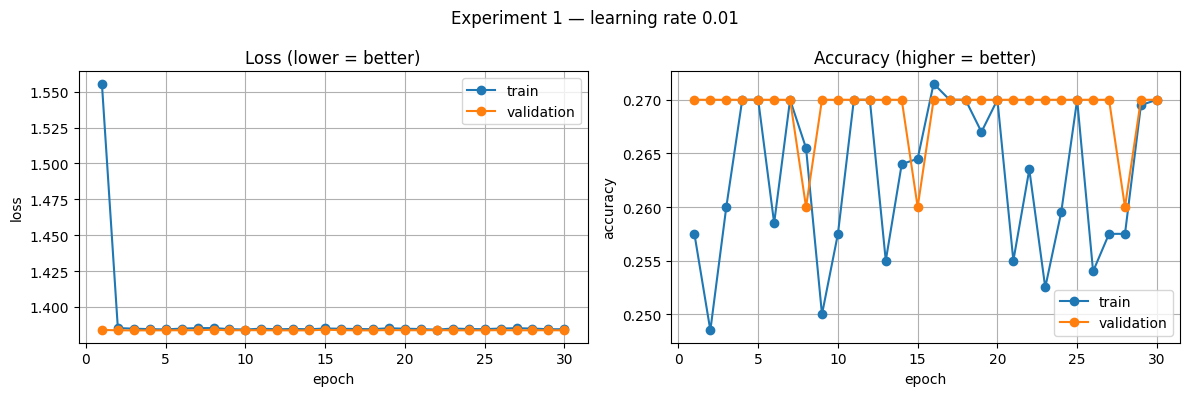

In [ ]:
# Experiment 1: learning rate 0.01
torch.manual_seed(0)
model_lr2 = SimpleCNN(p_dropout=0.5).to(device)

history_lr2 = train_model(model_lr2, train_loader_aug, val_loader_clean, epochs=30, lr=1e-2)
plot_history(history_lr2, "Experiment 1 — learning rate 0.01")

Epoch  1/30  train_loss=1.361 train_acc=0.330  |  val_loss=1.323 val_acc=0.444
Epoch  2/30  train_loss=1.267 train_acc=0.429  |  val_loss=1.186 val_acc=0.498
Epoch  3/30  train_loss=1.158 train_acc=0.495  |  val_loss=1.052 val_acc=0.576
Epoch  4/30  train_loss=1.061 train_acc=0.547  |  val_loss=0.968 val_acc=0.622
Epoch  5/30  train_loss=0.962 train_acc=0.606  |  val_loss=0.860 val_acc=0.662
Epoch  6/30  train_loss=0.921 train_acc=0.610  |  val_loss=0.850 val_acc=0.644
Epoch  7/30  train_loss=0.897 train_acc=0.621  |  val_loss=0.794 val_acc=0.664
Epoch  8/30  train_loss=0.858 train_acc=0.651  |  val_loss=0.830 val_acc=0.662
Epoch  9/30  train_loss=0.816 train_acc=0.660  |  val_loss=0.779 val_acc=0.662
Epoch 10/30  train_loss=0.798 train_acc=0.684  |  val_loss=0.731 val_acc=0.696
Epoch 11/30  train_loss=0.774 train_acc=0.674  |  val_loss=0.698 val_acc=0.718
Epoch 12/30  train_loss=0.768 train_acc=0.692  |  val_loss=0.692 val_acc=0.720
Epoch 13/30  train_loss=0.759 train_acc=0.682  |  va

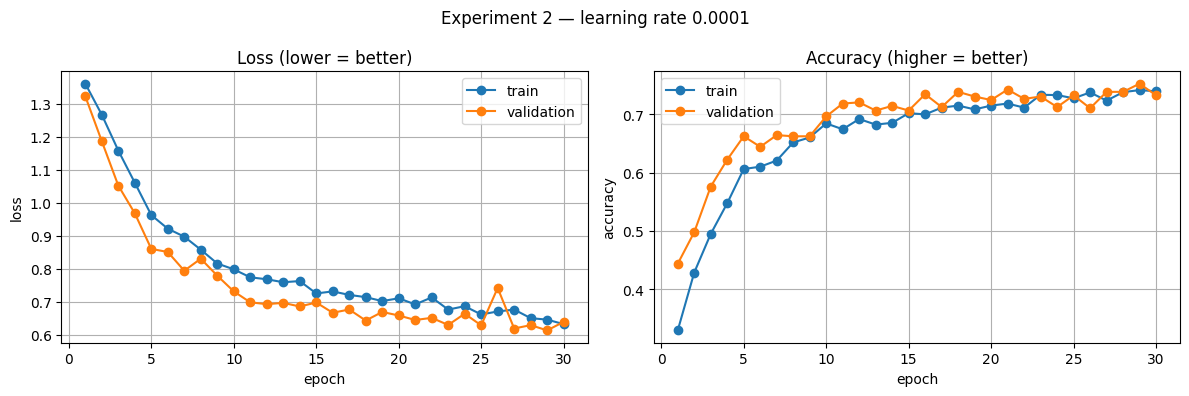

In [ ]:
# Experiment 2: learning rate 0.0001
torch.manual_seed(0)
model_lr4 = SimpleCNN(p_dropout=0.5).to(device)

history_lr4 = train_model(model_lr4, train_loader_aug, val_loader_clean, epochs=30, lr=1e-4)
plot_history(history_lr4, "Experiment 2 — learning rate 0.0001")

Epoch  1/30  train_loss=1.330 train_acc=0.345  |  val_loss=1.302 val_acc=0.374
Epoch  2/30  train_loss=1.199 train_acc=0.446  |  val_loss=1.138 val_acc=0.486
Epoch  3/30  train_loss=1.030 train_acc=0.546  |  val_loss=0.913 val_acc=0.618
Epoch  4/30  train_loss=0.868 train_acc=0.650  |  val_loss=0.776 val_acc=0.680
Epoch  5/30  train_loss=0.789 train_acc=0.680  |  val_loss=0.763 val_acc=0.698
Epoch  6/30  train_loss=0.765 train_acc=0.707  |  val_loss=0.660 val_acc=0.732
Epoch  7/30  train_loss=0.687 train_acc=0.717  |  val_loss=0.757 val_acc=0.710
Epoch  8/30  train_loss=0.682 train_acc=0.724  |  val_loss=0.634 val_acc=0.748
Epoch  9/30  train_loss=0.618 train_acc=0.751  |  val_loss=0.603 val_acc=0.772
Epoch 10/30  train_loss=0.623 train_acc=0.752  |  val_loss=0.652 val_acc=0.738
Epoch 11/30  train_loss=0.604 train_acc=0.758  |  val_loss=0.569 val_acc=0.778
Epoch 12/30  train_loss=0.576 train_acc=0.779  |  val_loss=0.606 val_acc=0.798
Epoch 13/30  train_loss=0.556 train_acc=0.780  |  va

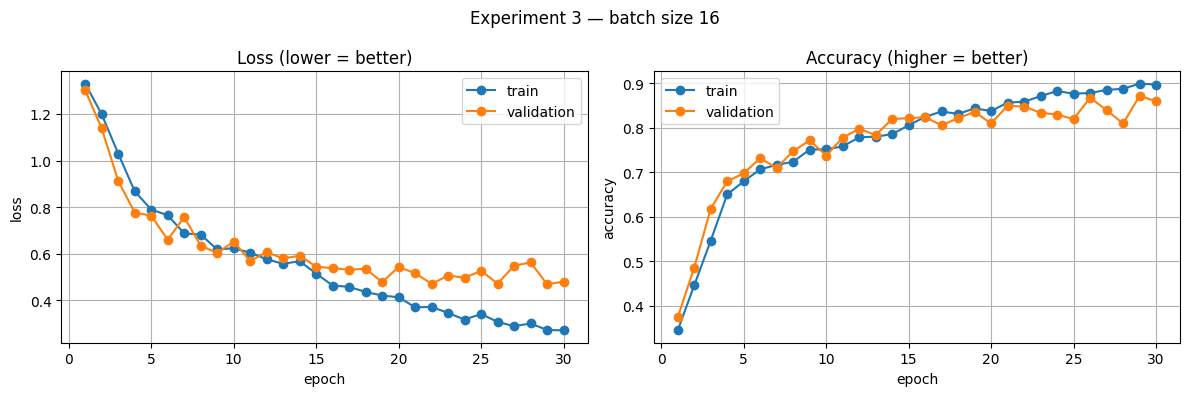

In [ ]:
# Experiment 3: batch size 16
train_loader_b16 = DataLoader(train_ds_aug, batch_size=16, shuffle=True)
val_loader_b16   = DataLoader(val_ds_clean, batch_size=16, shuffle=False)

torch.manual_seed(0)
model_b16 = SimpleCNN(p_dropout=0.5).to(device)

history_b16 = train_model(model_b16, train_loader_b16, val_loader_b16, epochs=30, lr=1e-3)
plot_history(history_b16, "Experiment 3 — batch size 16")

Epoch  1/30  train_loss=1.326 train_acc=0.359  |  val_loss=1.249 val_acc=0.432
Epoch  2/30  train_loss=1.181 train_acc=0.469  |  val_loss=1.067 val_acc=0.536
Epoch  3/30  train_loss=1.035 train_acc=0.568  |  val_loss=0.902 val_acc=0.616
Epoch  4/30  train_loss=0.936 train_acc=0.613  |  val_loss=0.785 val_acc=0.658
Epoch  5/30  train_loss=0.824 train_acc=0.660  |  val_loss=0.694 val_acc=0.722
Epoch  6/30  train_loss=0.780 train_acc=0.677  |  val_loss=0.676 val_acc=0.738
Epoch  7/30  train_loss=0.721 train_acc=0.705  |  val_loss=0.687 val_acc=0.728
Epoch  8/30  train_loss=0.751 train_acc=0.694  |  val_loss=0.623 val_acc=0.758
Epoch  9/30  train_loss=0.688 train_acc=0.728  |  val_loss=0.651 val_acc=0.750
Epoch 10/30  train_loss=0.676 train_acc=0.725  |  val_loss=0.602 val_acc=0.754
Epoch 11/30  train_loss=0.639 train_acc=0.745  |  val_loss=0.586 val_acc=0.778
Epoch 12/30  train_loss=0.602 train_acc=0.772  |  val_loss=0.560 val_acc=0.792
Epoch 13/30  train_loss=0.600 train_acc=0.778  |  va

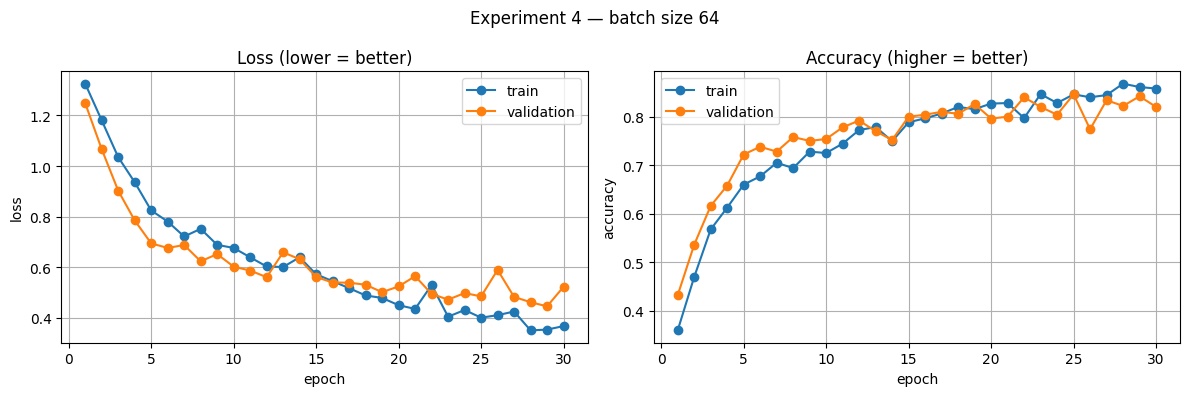

In [ ]:
# Experiment 4: batch size 64
train_loader_b64 = DataLoader(train_ds_aug, batch_size=64, shuffle=True)
val_loader_b64   = DataLoader(val_ds_clean, batch_size=64, shuffle=False)

torch.manual_seed(0)
model_b64 = SimpleCNN(p_dropout=0.5).to(device)

history_b64 = train_model(model_b64, train_loader_b64, val_loader_b64, epochs=30, lr=1e-3)
plot_history(history_b64, "Experiment 4 — batch size 64")

Epoch  1/30  train_loss=1.286 train_acc=0.397  |  val_loss=1.224 val_acc=0.446
Epoch  2/30  train_loss=1.099 train_acc=0.524  |  val_loss=1.009 val_acc=0.562
Epoch  3/30  train_loss=0.936 train_acc=0.597  |  val_loss=0.830 val_acc=0.642
Epoch  4/30  train_loss=0.844 train_acc=0.651  |  val_loss=0.757 val_acc=0.698
Epoch  5/30  train_loss=0.746 train_acc=0.700  |  val_loss=0.678 val_acc=0.716
Epoch  6/30  train_loss=0.697 train_acc=0.731  |  val_loss=0.618 val_acc=0.738
Epoch  7/30  train_loss=0.664 train_acc=0.737  |  val_loss=0.620 val_acc=0.748
Epoch  8/30  train_loss=0.638 train_acc=0.742  |  val_loss=0.576 val_acc=0.778
Epoch  9/30  train_loss=0.576 train_acc=0.773  |  val_loss=0.590 val_acc=0.780
Epoch 10/30  train_loss=0.588 train_acc=0.779  |  val_loss=0.538 val_acc=0.808
Epoch 11/30  train_loss=0.519 train_acc=0.800  |  val_loss=0.544 val_acc=0.790
Epoch 12/30  train_loss=0.510 train_acc=0.807  |  val_loss=0.509 val_acc=0.800
Epoch 13/30  train_loss=0.499 train_acc=0.808  |  va

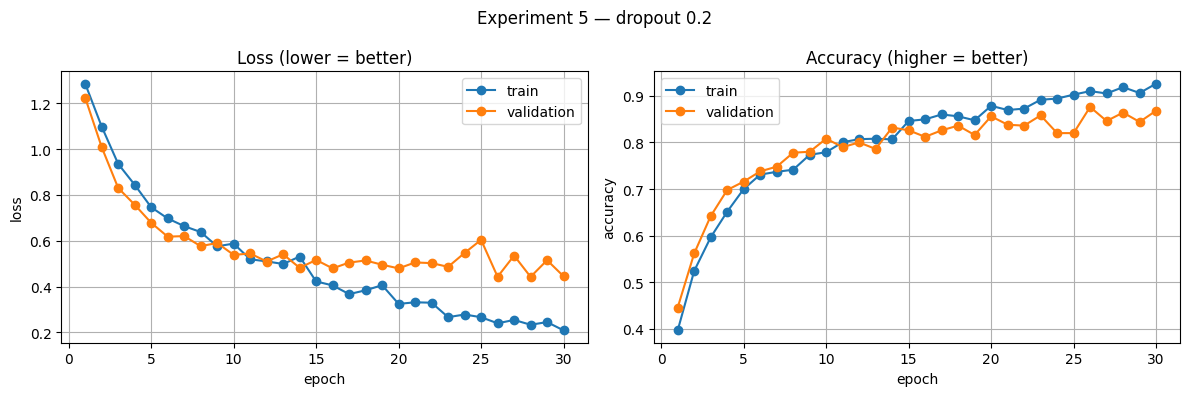

In [ ]:
# Experiment 5: dropout 0.2
torch.manual_seed(0)
model_d02 = SimpleCNN(p_dropout=0.2).to(device)

history_d02 = train_model(model_d02, train_loader_aug, val_loader_clean, epochs=30, lr=1e-3)
plot_history(history_d02, "Experiment 5 — dropout 0.2")

Epoch  1/30  train_loss=1.181 train_acc=0.477  |  val_loss=1.053 val_acc=0.518
Epoch  2/30  train_loss=0.932 train_acc=0.617  |  val_loss=0.799 val_acc=0.700
Epoch  3/30  train_loss=0.682 train_acc=0.723  |  val_loss=0.633 val_acc=0.744
Epoch  4/30  train_loss=0.616 train_acc=0.746  |  val_loss=0.578 val_acc=0.764
Epoch  5/30  train_loss=0.555 train_acc=0.782  |  val_loss=0.588 val_acc=0.754
Epoch  6/30  train_loss=0.491 train_acc=0.816  |  val_loss=0.638 val_acc=0.750
Epoch  7/30  train_loss=0.388 train_acc=0.849  |  val_loss=0.709 val_acc=0.748
Epoch  8/30  train_loss=0.388 train_acc=0.860  |  val_loss=0.647 val_acc=0.746
Epoch  9/30  train_loss=0.273 train_acc=0.905  |  val_loss=0.508 val_acc=0.802
Epoch 10/30  train_loss=0.215 train_acc=0.926  |  val_loss=0.540 val_acc=0.818
Epoch 11/30  train_loss=0.204 train_acc=0.928  |  val_loss=0.484 val_acc=0.838
Epoch 12/30  train_loss=0.153 train_acc=0.950  |  val_loss=0.673 val_acc=0.822
Epoch 13/30  train_loss=0.157 train_acc=0.939  |  va

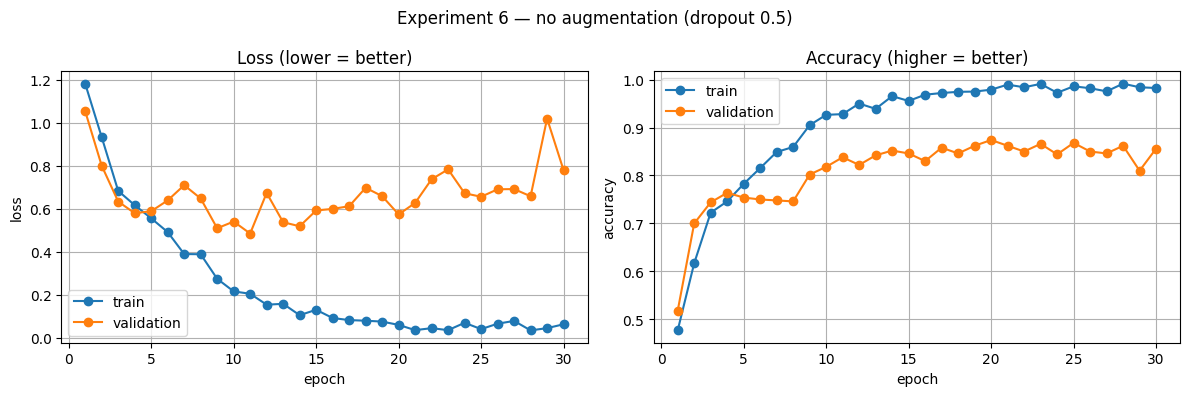

In [ ]:
# Experiment 6: no augmentation, dropout 0.5
torch.manual_seed(0)
model_noaug = SimpleCNN(p_dropout=0.5).to(device)

history_noaug = train_model(model_noaug, train_loader, val_loader, epochs=30, lr=1e-3)
plot_history(history_noaug, "Experiment 6 — no augmentation (dropout 0.5)")

Epoch  1/30  train_loss=1.329 train_acc=0.347  |  val_loss=1.229 val_acc=0.446
Epoch  2/30  train_loss=1.158 train_acc=0.489  |  val_loss=1.007 val_acc=0.588
Epoch  3/30  train_loss=1.075 train_acc=0.536  |  val_loss=0.955 val_acc=0.588
Epoch  4/30  train_loss=0.959 train_acc=0.584  |  val_loss=0.884 val_acc=0.578
Epoch  5/30  train_loss=0.877 train_acc=0.638  |  val_loss=0.963 val_acc=0.604
Epoch  6/30  train_loss=0.838 train_acc=0.657  |  val_loss=0.797 val_acc=0.682
Epoch  7/30  train_loss=0.809 train_acc=0.660  |  val_loss=0.713 val_acc=0.740
Epoch  8/30  train_loss=0.764 train_acc=0.692  |  val_loss=0.677 val_acc=0.746
Epoch  9/30  train_loss=0.721 train_acc=0.716  |  val_loss=0.693 val_acc=0.730
Epoch 10/30  train_loss=0.704 train_acc=0.719  |  val_loss=0.616 val_acc=0.756
Epoch 11/30  train_loss=0.674 train_acc=0.732  |  val_loss=0.652 val_acc=0.754
Epoch 12/30  train_loss=0.644 train_acc=0.746  |  val_loss=0.662 val_acc=0.756
Epoch 13/30  train_loss=0.637 train_acc=0.752  |  va

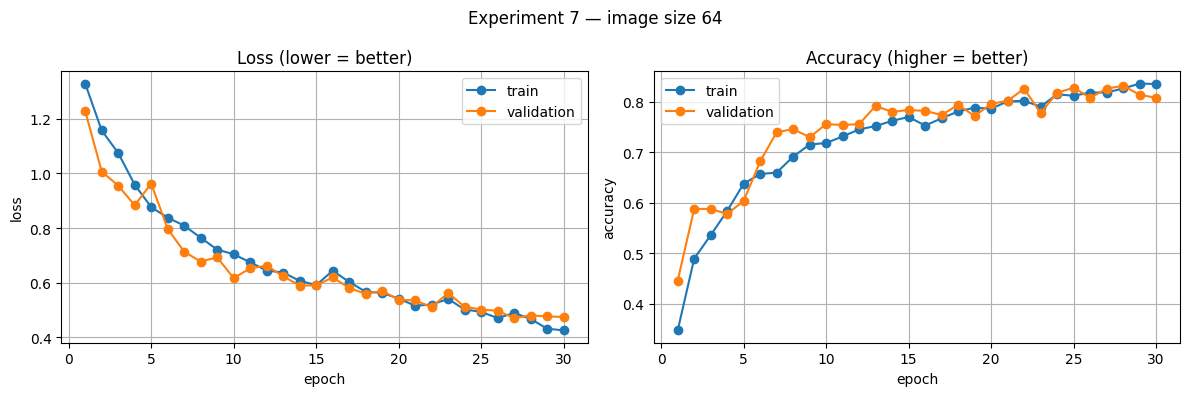

In [ ]:
# Experiment 7: image size 64 -> before 128
IMG_64 = 64


train_transform_64 = transforms.Compose([
    transforms.Resize((IMG_64, IMG_64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
])
val_transform_64 = transforms.Compose([
    transforms.Resize((IMG_64, IMG_64)),
    transforms.ToTensor(),
])

train_ds_64 = datasets.ImageFolder(train_dir, transform=train_transform_64)
val_ds_64   = datasets.ImageFolder(val_dir,   transform=val_transform_64)
train_loader_64 = DataLoader(train_ds_64, batch_size=BATCH_SIZE, shuffle=True)
val_loader_64   = DataLoader(val_ds_64,   batch_size=BATCH_SIZE, shuffle=False)


torch.manual_seed(0)
model_64 = SimpleCNN(p_dropout=0.5).to(device)
model_64.fc1 = nn.Linear(64 * 8 * 8, 128).to(device)   # 64 -> 32 -> 16 -> 8

history_64 = train_model(model_64, train_loader_64, val_loader_64, epochs=30, lr=1e-3)
plot_history(history_64, "Experiment 7 — image size 64")

Epoch  1/30  train_loss=1.326 train_acc=0.333  |  val_loss=1.231 val_acc=0.380
Epoch  2/30  train_loss=1.119 train_acc=0.512  |  val_loss=0.934 val_acc=0.596
Epoch  3/30  train_loss=0.985 train_acc=0.587  |  val_loss=0.921 val_acc=0.628
Epoch  4/30  train_loss=0.882 train_acc=0.635  |  val_loss=0.761 val_acc=0.698
Epoch  5/30  train_loss=0.798 train_acc=0.681  |  val_loss=0.696 val_acc=0.714
Epoch  6/30  train_loss=0.762 train_acc=0.698  |  val_loss=0.737 val_acc=0.736
Epoch  7/30  train_loss=0.720 train_acc=0.717  |  val_loss=0.608 val_acc=0.782
Epoch  8/30  train_loss=0.690 train_acc=0.724  |  val_loss=0.646 val_acc=0.752
Epoch  9/30  train_loss=0.657 train_acc=0.748  |  val_loss=0.632 val_acc=0.784
Epoch 10/30  train_loss=0.613 train_acc=0.761  |  val_loss=0.754 val_acc=0.684
Epoch 11/30  train_loss=0.608 train_acc=0.765  |  val_loss=0.569 val_acc=0.778
Epoch 12/30  train_loss=0.539 train_acc=0.793  |  val_loss=0.609 val_acc=0.774
Epoch 13/30  train_loss=0.524 train_acc=0.804  |  va

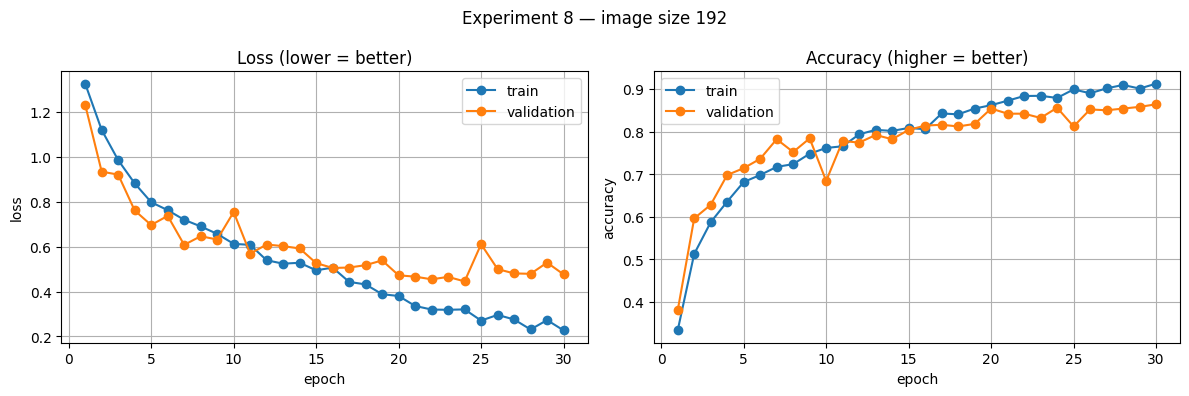

In [ ]:
# Experiment 8: image size 192 -> before 128
IMG_192 = 192


train_transform_192 = transforms.Compose([
    transforms.Resize((IMG_192, IMG_192)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
])
val_transform_192 = transforms.Compose([
    transforms.Resize((IMG_192, IMG_192)),
    transforms.ToTensor(),
])

train_ds_192 = datasets.ImageFolder(train_dir, transform=train_transform_192)
val_ds_192   = datasets.ImageFolder(val_dir,   transform=val_transform_192)
train_loader_192 = DataLoader(train_ds_192, batch_size=BATCH_SIZE, shuffle=True)
val_loader_192   = DataLoader(val_ds_192,   batch_size=BATCH_SIZE, shuffle=False)


torch.manual_seed(0)
model_192 = SimpleCNN(p_dropout=0.5).to(device)
model_192.fc1 = nn.Linear(64 * 24 * 24, 128).to(device)   # 192 -> 96 -> 48 -> 24

history_192 = train_model(model_192, train_loader_192, val_loader_192, epochs=30, lr=1e-3)
plot_history(history_192, "Experiment 8 — image size 192")

In [ ]:
import pandas as pd

experiments = {
    "Exp 0: Baseline (lr 0.001, batch 32, drop 0.5, aug, 128px)": history_base,
    "Exp 1: LR 0.01":               history_lr2,
    "Exp 2: LR 0.0001":             history_lr4,
    "Exp 3: Batch 16":              history_b16,
    "Exp 4: Batch 64":              history_b64,
    "Exp 5: Dropout 0.2":           history_d02,
    "Exp 6: No augmentation":       history_noaug,
    "Exp 7: Image 64":              history_64,
    "Exp 8: Image 192":             history_192,
}

rows = []
for name, h in experiments.items():
    best_ep = int(np.argmax(h["val_acc"]))
    rows.append({
        "Experiment":       name,
        "Best val acc":     round(h["val_acc"][best_ep], 3),
        "Best epoch":       best_ep + 1,
        "Min val loss":     round(min(h["val_loss"]), 3),
        "Final train acc":  round(h["train_acc"][-1], 3),
        "Final val acc":    round(h["val_acc"][-1], 3),
        "Final gap":        round(h["train_acc"][-1] - h["val_acc"][-1], 3),
    })

summary = pd.DataFrame(rows)
summary

,Experiment,Best val acc,Best epoch,Min val loss,Final train acc,Final val acc,Final gap
0,"Exp 0: Baseline (lr 0.001, batch 32, drop 0.5,...",0.854,26,0.433,0.908,0.842,0.067
1,Exp 1: LR 0.01,0.270,1,1.384,0.270,0.270,0.000
2,Exp 2: LR 0.0001,0.752,29,0.613,0.739,0.732,0.007
3,Exp 3: Batch 16,0.872,29,0.468,0.897,0.860,0.037
4,Exp 4: Batch 64,0.846,25,0.445,0.858,0.820,0.038
5,Exp 5: Dropout 0.2,0.876,26,0.442,0.926,0.868,0.058
6,Exp 6: No augmentation,0.874,20,0.484,0.983,0.856,0.127
7,Exp 7: Image 64,0.832,28,0.470,0.836,0.808,0.027
8,Exp 8: Image 192,0.864,30,0.445,0.912,0.864,0.048


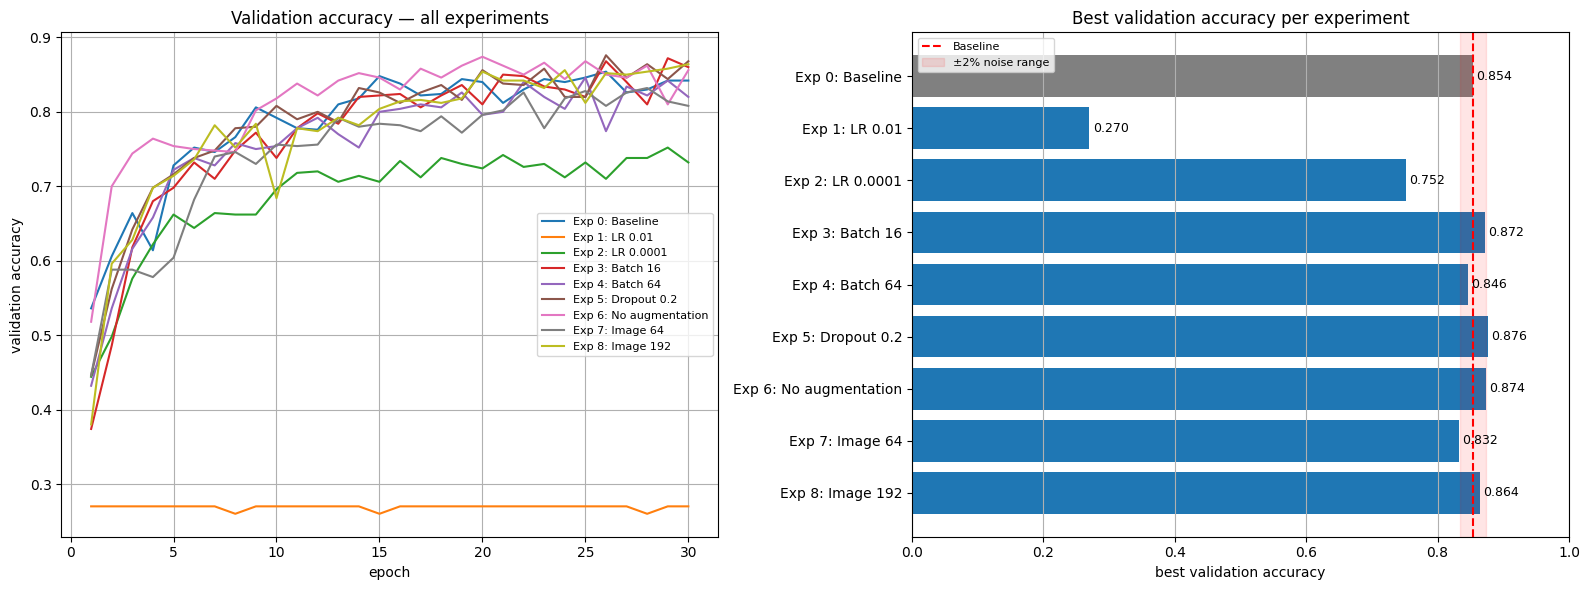

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))


for name, h in experiments.items():
    ax1.plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], label=name.split(" (")[0])
ax1.set_title("Validation accuracy — all experiments")
ax1.set_xlabel("epoch"); ax1.set_ylabel("validation accuracy")
ax1.legend(fontsize=8); ax1.grid(True)


names = [n.split(" (")[0] for n in summary["Experiment"]]
best  = summary["Best val acc"]
colors = ["gray" if i == 0 else "tab:blue" for i in range(len(names))]
ax2.barh(names, best, color=colors)
ax2.axvline(best[0], color="red", linestyle="--", label="Baseline")
ax2.axvspan(best[0] - 0.02, best[0] + 0.02, color="red", alpha=0.1, label="±2% noise range")
for i, v in enumerate(best):
    ax2.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
ax2.set_title("Best validation accuracy per experiment")
ax2.set_xlabel("best validation accuracy"); ax2.set_xlim(0, 1)
ax2.invert_yaxis(); ax2.legend(fontsize=8); ax2.grid(True, axis="x")

plt.tight_layout()
plt.show()